In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as mlt
import seaborn as sb

Importing Data Files

In [3]:
df=pd.read_csv("Attack_Dataset.csv")

Basic understanding

In [4]:
df.head(5)

,ID,Title,Category,Attack Type,Scenario Description,Tools Used,Attack Steps,Target Type,Vulnerability,MITRE Technique,Impact,Detection Method,Solution,Tags,Source,Unnamed: 15
0,1,Authentication Bypass via SQL Injection,Mobile Security,SQL Injection (SQLi),A login form fails to validate or sanitize inp...,"Browser, Burp Suite, SQLMap",1. Reconnaissance: Find a login form on the we...,"Web Login Portals (e.g., banking, admin dashbo...",Unsanitized input fields in SQL queries,"T1078 (Valid Accounts), T1190 (Exploit Public-...","Full account takeover, data theft, privilege e...","Web server logs, anomaly detection (e.g., logi...","Use prepared statements, Sanitize inputs, Limi...","SQLi, Authentication Bypass, Web Security, OWA...","OWASP, MITRE ATT&CK, DVWA",NaN
1,2,Union-Based SQL Injection,AI Agents & LLM Exploits,SQL Injection,This attack occurs when a hacker uses the SQL ...,"SQLMap, Burp Suite, Havij, Browser Developer T...",1. Identify User Input Points: Attacker finds ...,"Web Applications, Login Pages, Search Forms",Improperly filtered input fields that allow SQ...,T1190 – Exploit Public-Facing Application,"Data leakage, Credential theft, Account takeov...",Web Application Firewalls (WAF)Log AnalysisInp...,Use parameterized queries (Prepared Statements...,#SQLInjection #WebSecurity #UnionAttack #OWASP...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger Web...",NaN
2,3,Error-Based SQL Injection,AI Agents & LLM Exploits,SQL Injection,This attack occurs when an attacker intentiona...,"SQLMap, Burp Suite, Manual Browser Testing, Havij",1. Identify Input Points:Attacker finds a fiel...,"Web Applications, Login Forms, URL Parameters,...",Error message exposure due to lack of input va...,T1190 – Exploit Public-Facing Application,"Information disclosure, Database structure exp...",Review and monitor error logsEnable generic er...,Turn off detailed error messages in production...,#SQLInjection #ErrorLeakage #WebAppSecurity #O...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger Web...",NaN
3,4,Blind SQL Injection,AI Agents & LLM Exploits,SQL Injection,"In Blind SQL Injection, the attacker doesn’t s...","SQLMap, Burp Suite, sqlninja, Manual Browser T...",1. Find a User Input Point:Attacker finds a pl...,"Web Applications, Login Pages, Search Fields, ...","No error messages, but user input is still pas...",T1190 – Exploit Public-Facing Application,Slow and stealthy data theftFull database comp...,Monitor for slow and repetitive requestsAnalyz...,Use parameterized queries (prepared statements...,#BlindSQLi #TimeBasedSQLi #WebAppSecurity #OWA...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger, SQ...",NaN
4,5,Second-Order SQL Injection,AI Agents & LLM Exploits,SQL Injection,"In a Second-Order SQL Injection, the attacker ...","Burp Suite, SQLMap, Postman, Browser Dev Tools...",1. Identify Stored Input Fields:The attacker l...,"Web Applications, User Registration Forms, Pro...",Trusting previously stored unvalidated data in...,T1505.003 – SQL Injection,Delayed data theftUnexpected system behaviorSe...,Log monitoring for delayed query failuresTrack...,Sanitize and validate inputs both at entry and...,#SecondOrderSQLi #DelayedInjection #StoredInje...,"OWASP, MITRE ATT&CK, PortSwigger Academy, Acun...",NaN


In [5]:
df.columns

Index(['ID', 'Title', 'Category', 'Attack Type', 'Scenario Description',
       'Tools Used', 'Attack Steps ', 'Target Type', 'Vulnerability',
       'MITRE Technique', 'Impact', 'Detection Method', 'Solution', 'Tags',
       'Source', 'Unnamed: 15'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14133 entries, 0 to 14132
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   ID                    14133 non-null  int64 
 1   Title                 14133 non-null  object
 2   Category              14133 non-null  object
 3   Attack Type           14133 non-null  object
 4   Scenario Description  14133 non-null  object
 5   Tools Used            14119 non-null  object
 6   Attack Steps          14133 non-null  object
 7   Target Type           14129 non-null  object
 8   Vulnerability         14115 non-null  object
 9   MITRE Technique       14109 non-null  object
 10  Impact                14130 non-null  object
 11  Detection Method      14129 non-null  object
 12  Solution              14130 non-null  object
 13  Tags                  14130 non-null  object
 14  Source                13973 non-null  object
 15  Unnamed: 15           46 non-null   

In [7]:
df["Source"].unique()

array(['OWASP, MITRE ATT&CK, DVWA',
       'OWASP, MITRE ATT&CK, Acunetix, PortSwigger Web Security Academy',
       'OWASP, MITRE ATT&CK, Acunetix, PortSwigger, SQLMap Docs', ...,
       'National Lab', 'Internal Tools', 'Open Satellite Consortium'],
      dtype=object)

In [8]:
df.describe()

,ID
count,14133.000000
mean,7067.000000
std,4079.990012
min,1.000000
25%,3534.000000
50%,7067.000000
75%,10600.000000
max,14133.000000


In [9]:
df.size

226128

In [10]:
df.shape

(14133, 16)

In [11]:
#selecting the needable colunms only
df=df.drop(columns=["ID","Title","Tags","Unnamed: 15"])

In [12]:
print(list(df.columns),end=" ")

['Category', 'Attack Type', 'Scenario Description', 'Tools Used', 'Attack Steps ', 'Target Type', 'Vulnerability', 'MITRE Technique', 'Impact', 'Detection Method', 'Solution', 'Source'] 

In [13]:
df.head()

,Category,Attack Type,Scenario Description,Tools Used,Attack Steps,Target Type,Vulnerability,MITRE Technique,Impact,Detection Method,Solution,Source
0,Mobile Security,SQL Injection (SQLi),A login form fails to validate or sanitize inp...,"Browser, Burp Suite, SQLMap",1. Reconnaissance: Find a login form on the we...,"Web Login Portals (e.g., banking, admin dashbo...",Unsanitized input fields in SQL queries,"T1078 (Valid Accounts), T1190 (Exploit Public-...","Full account takeover, data theft, privilege e...","Web server logs, anomaly detection (e.g., logi...","Use prepared statements, Sanitize inputs, Limi...","OWASP, MITRE ATT&CK, DVWA"
1,AI Agents & LLM Exploits,SQL Injection,This attack occurs when a hacker uses the SQL ...,"SQLMap, Burp Suite, Havij, Browser Developer T...",1. Identify User Input Points: Attacker finds ...,"Web Applications, Login Pages, Search Forms",Improperly filtered input fields that allow SQ...,T1190 – Exploit Public-Facing Application,"Data leakage, Credential theft, Account takeov...",Web Application Firewalls (WAF)Log AnalysisInp...,Use parameterized queries (Prepared Statements...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger Web..."
2,AI Agents & LLM Exploits,SQL Injection,This attack occurs when an attacker intentiona...,"SQLMap, Burp Suite, Manual Browser Testing, Havij",1. Identify Input Points:Attacker finds a fiel...,"Web Applications, Login Forms, URL Parameters,...",Error message exposure due to lack of input va...,T1190 – Exploit Public-Facing Application,"Information disclosure, Database structure exp...",Review and monitor error logsEnable generic er...,Turn off detailed error messages in production...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger Web..."
3,AI Agents & LLM Exploits,SQL Injection,"In Blind SQL Injection, the attacker doesn’t s...","SQLMap, Burp Suite, sqlninja, Manual Browser T...",1. Find a User Input Point:Attacker finds a pl...,"Web Applications, Login Pages, Search Fields, ...","No error messages, but user input is still pas...",T1190 – Exploit Public-Facing Application,Slow and stealthy data theftFull database comp...,Monitor for slow and repetitive requestsAnalyz...,Use parameterized queries (prepared statements...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger, SQ..."
4,AI Agents & LLM Exploits,SQL Injection,"In a Second-Order SQL Injection, the attacker ...","Burp Suite, SQLMap, Postman, Browser Dev Tools...",1. Identify Stored Input Fields:The attacker l...,"Web Applications, User Registration Forms, Pro...",Trusting previously stored unvalidated data in...,T1505.003 – SQL Injection,Delayed data theftUnexpected system behaviorSe...,Log monitoring for delayed query failuresTrack...,Sanitize and validate inputs both at entry and...,"OWASP, MITRE ATT&CK, PortSwigger Academy, Acun..."


Data cleaning

In [14]:
#checking null values
df.isna().sum()

Category                  0
Attack Type               0
Scenario Description      0
Tools Used               14
Attack Steps              0
Target Type               4
Vulnerability            18
MITRE Technique          24
Impact                    3
Detection Method          4
Solution                  3
Source                  160
dtype: int64

In [15]:
#removing null values
df=df.dropna(subset=["Target Type","Impact","Detection Method","Solution"])

In [16]:
#filling null value
df["Tools Used"]=df["Tools Used"].fillna(df["Tools Used"].mode()[0])

In [17]:
df["Vulnerability"]=df["Vulnerability"].fillna(df["Vulnerability"].mode()[0])

In [18]:
df["MITRE Technique"]=df["MITRE Technique"].fillna(df["MITRE Technique"].mode()[0])

In [19]:
df=df.dropna(subset=["Source"])

In [20]:
df.isna().sum()

Category                0
Attack Type             0
Scenario Description    0
Tools Used              0
Attack Steps            0
Target Type             0
Vulnerability           0
MITRE Technique         0
Impact                  0
Detection Method        0
Solution                0
Source                  0
dtype: int64

In [21]:
#checking duplicates
df.duplicated().sum()

238

In [22]:
#removing duplicate
df=df.drop_duplicates()

In [23]:
#checking data types
df.dtypes

Category                object
Attack Type             object
Scenario Description    object
Tools Used              object
Attack Steps            object
Target Type             object
Vulnerability           object
MITRE Technique         object
Impact                  object
Detection Method        object
Solution                object
Source                  object
dtype: object

In [24]:
#The target colunm is text data with long content so categarizeing them
def cat_solutions(x):
    x=x.lower()
    if "validation" in x or "sanitize" in x or "invalidate input" in x:
        return "input validation"
    if "error message" in x or "error handling" in x or "logs" in x:
        return "error handling"
    if "waf" in x or "ids/ips" in x or "firewall" in x or "detection" in x:
        return "firewall/detection"
    if "passwords" in x or "mfa" in x or "access control" in x or "authentication" in x:
        return "authentication/access control"
    if "update" in x or "software" in x or "security" in x or "configurations" in x:
        return "configuration managment"
    if "tls" in x or "https" in x or "encrypt" in x or "sensitive" in x:
        return "encryption/data protection"

In [25]:
df["Solution"]=df["Solution"].apply(cat_solutions)

In [26]:
df["Solution"].value_counts()

Solution
input validation                 1163
encryption/data protection        964
authentication/access control     473
firewall/detection                466
configuration managment           464
error handling                    234
Name: count, dtype: int64

In [27]:
#There are lot of unbalanced value in target column so
#apart from oversampling and undersampling i use the class weight methond in unbalanced data
from sklearn.utils.class_weight import compute_class_weight
class_cata=df["Solution"].unique()
weight=compute_class_weight(class_weight="balanced",classes=np.array(class_cata),y=df["Solution"])
class_weights=dict(zip(class_cata,weight))
print(class_weights)

{'input validation': 1.6868935020267781, 'configuration managment': 4.22814039408867, 'encryption/data protection': 2.0351215174866626, None: 0.19679578120745742, 'firewall/detection': 4.209993868792152, 'error handling': 8.384004884004884, 'authentication/access control': 4.147689519782543}


Data Preprocess

In [28]:
import string
import emoji
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
def data_processing(text):
    #lowering
    data=text.lower()
    data=emoji.demojize(data)
    data=data.replace("→"," ")
    #token akki
    token=data.split()
    #punc
    data=[i.strip(string.punctuation) for i in token]
    #stop word
    stop=stopwords.words("english")
    data=[i for i in data if i not in stop and i!=" "]
    # stemming
    WNL=WordNetLemmatizer()
    root=(WNL.lemmatize(i,pos="v") for i in data)
    result=" ".join(root)
    return result

In [29]:
df["Vulnerability"]=df["Vulnerability"].apply(data_processing)

In [30]:
df["Scenario Description"]=df["Scenario Description"].apply(data_processing)

In [31]:
df["Scenario Description"].unique()

array(['login form fail validate sanitize input allow attackers log admin without know password',
       'attack occur hacker use sql union operator combine result malicious query legitimate one often gain access hide data database vulnerable web application',
       'attack occur attacker intentionally trigger database errors extract information errors often reveal hide data database structure help attackers steal credentials plan attack',
       ...,
       'create secure national simulation environment test space cyber threats',
       'design scanner tailor satellite firmware vulnerability detection',
       'measure alignment cyber standards across 25 countries satellite program'],
      dtype=object)

In [32]:
df["Attack Steps "]=df["Attack Steps "].apply(data_processing)

In [33]:
df["Category"]=df["Category"].apply(data_processing)

In [34]:
df["Attack Steps "].unique()

array(["1 reconnaissance find login form website e.g username password field 2 test injection enter simple payload like  1'='1 username password field 3 analyze response login succeed error message change may vulnerable 4 craft exploit use payloads like username  1'='1  password anything 5 bypass authentication sql query behind scenes become select  users username 1'='1   password='anything always return true 1=1 trick system log without password 6 access grant attacker get access admin user account",
       '1 identify user input point attacker find search bar login form url interact database 2 test vulnerability attacker input single quote  break query error message unusual behavior occur may vulnerable 3 use union operator attacker try use union select combine query original one reveal additional columns/data 4 find number columns attacker use trick like order trial-and-error union select null,null match column count original query 5 extract data match attacker replace null value us

In [35]:
list(df.columns)

['Category',
 'Attack Type',
 'Scenario Description',
 'Tools Used',
 'Attack Steps ',
 'Target Type',
 'Vulnerability',
 'MITRE Technique',
 'Impact',
 'Detection Method',
 'Solution',
 'Source']

In [36]:
df["Source"].unique()

array(['OWASP, MITRE ATT&CK, DVWA',
       'OWASP, MITRE ATT&CK, Acunetix, PortSwigger Web Security Academy',
       'OWASP, MITRE ATT&CK, Acunetix, PortSwigger, SQLMap Docs', ...,
       'National Lab', 'Internal Tools', 'Open Satellite Consortium'],
      dtype=object)

In [37]:
df=df.rename(columns={"Solution":"Solution_cata"})

In [38]:
df[["Solution_cata"]]

,Solution_cata
0,input validation
1,input validation
2,input validation
3,input validation
4,input validation
...,...
14128,None
14129,None
14130,None
14131,None


Colunmtransform

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,LabelEncoder
from sklearn.pipeline import Pipeline

In [40]:
preprocesser=ColumnTransformer(
    transformers=[("text1",TfidfVectorizer(),"Category"),
                  ("text2",TfidfVectorizer(),"Attack Type"),
                  ("text3",TfidfVectorizer(),"Scenario Description"),
              ("text4",TfidfVectorizer(),"Vulnerability"),
              ("text5",TfidfVectorizer(),"Impact"),
              ("text6",TfidfVectorizer(),"Detection Method"),
              ("OneHotEncoder",OneHotEncoder(handle_unknown="ignore"),["Tools Used","Attack Steps ","Target Type","MITRE Technique","Source"])])

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score
from sklearn.model_selection import train_test_split

In [42]:
x=df.drop(columns="Solution_cata")
le=LabelEncoder()
y=le.fit_transform(df["Solution_cata"])
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.3)

In [43]:
model=[LogisticRegression(class_weight="balanced"),SVC(class_weight="balanced"),DecisionTreeClassifier(class_weight="balanced"),RandomForestClassifier(class_weight="balanced")]

LogisticRegression(class_weight='balanced')
**********
72
              precision    recall  f1-score   support

           0       0.30      0.25      0.27       324
           1       0.41      0.14      0.21       339
           2       0.44      0.34      0.38       679
           3       0.33      0.06      0.10       172
           4       0.32      0.15      0.20       324
           5       0.40      0.37      0.38       822
           6       0.80      0.89      0.84      6954

    accuracy                           0.72      9614
   macro avg       0.43      0.31      0.34      9614
weighted avg       0.68      0.72      0.69      9614



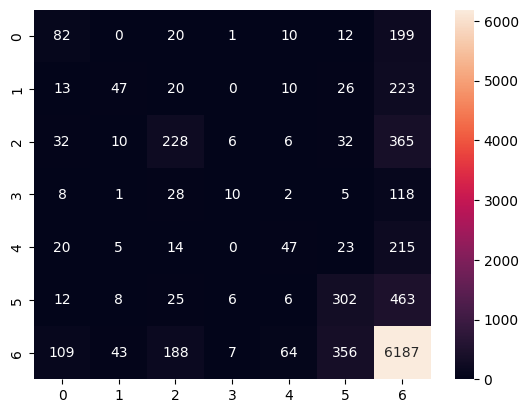

**********
SVC(class_weight='balanced')
**********
66
              precision    recall  f1-score   support

           0       0.41      0.19      0.26       324
           1       0.44      0.06      0.10       339
           2       0.34      0.37      0.35       679
           3       0.50      0.01      0.02       172
           4       0.36      0.13      0.19       324
           5       0.26      0.56      0.36       822
           6       0.81      0.79      0.80      6954

    accuracy                           0.66      9614
   macro avg       0.44      0.30      0.30      9614
weighted avg       0.68      0.66      0.65      9614



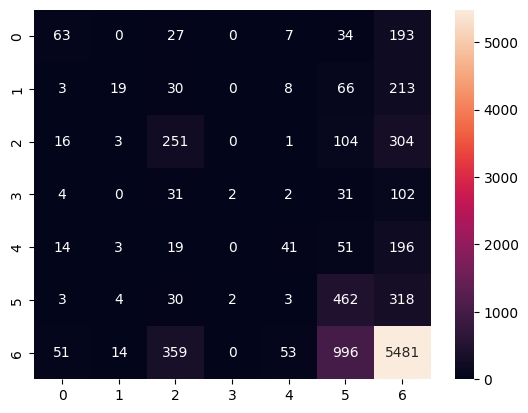

**********
DecisionTreeClassifier(class_weight='balanced')
**********
53
              precision    recall  f1-score   support

           0       0.11      0.16      0.13       324
           1       0.15      0.19      0.17       339
           2       0.16      0.22      0.18       679
           3       0.07      0.12      0.09       172
           4       0.09      0.12      0.10       324
           5       0.19      0.26      0.22       822
           6       0.77      0.65      0.71      6954

    accuracy                           0.53      9614
   macro avg       0.22      0.25      0.23      9614
weighted avg       0.60      0.53      0.56      9614



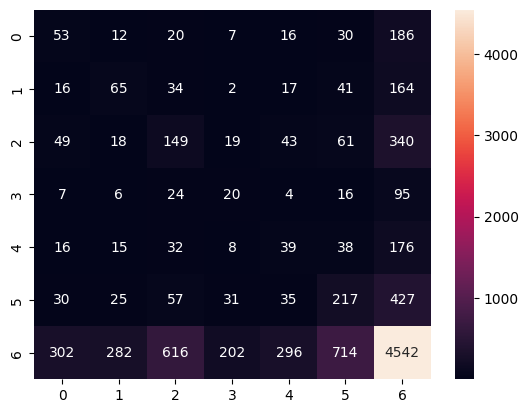

**********
RandomForestClassifier(class_weight='balanced')
**********
73
              precision    recall  f1-score   support

           0       0.75      0.01      0.02       324
           1       0.75      0.01      0.02       339
           2       0.83      0.01      0.01       679
           3       0.00      0.00      0.00       172
           4       0.00      0.00      0.00       324
           5       0.80      0.01      0.03       822
           6       0.73      1.00      0.84      6954

    accuracy                           0.73      9614
   macro avg       0.55      0.15      0.13      9614
weighted avg       0.70      0.73      0.61      9614



C:\Users\Sajin S\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Sajin S\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Sajin S\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitaliz

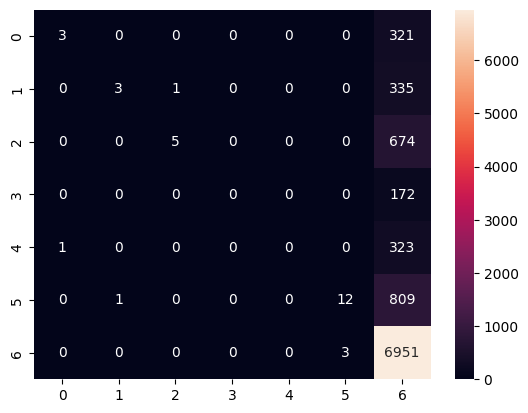

**********


In [44]:
for i in model:
    pipeline=Pipeline(steps=
                      [("preprocesser",preprocesser),
                       ("model",i)])
    pipeline.fit(x_train,y_train)
    y_pred=pipeline.predict(x_test)
    print(i)
    print("*"*10)
    print(round(accuracy_score(y_test,y_pred)*100))
    print(classification_report(y_test,y_pred,))
    sb.heatmap(confusion_matrix(y_test,y_pred),annot=True,fmt="d")
    mlt.show()
    print("*"*10)
    

Randomforest
**********
72
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       324
           1       1.00      0.01      0.01       339
           2       1.00      0.00      0.01       679
           3       0.00      0.00      0.00       172
           4       0.00      0.00      0.00       324
           5       0.73      0.01      0.02       822
           6       0.72      1.00      0.84      6954

    accuracy                           0.72      9614
   macro avg       0.49      0.15      0.13      9614
weighted avg       0.69      0.72      0.61      9614



C:\Users\Sajin S\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Sajin S\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Sajin S\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitaliz

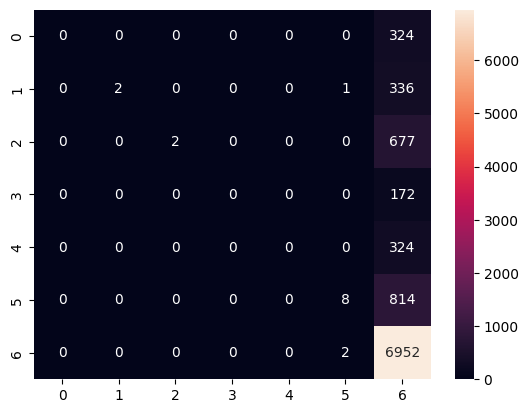

**********


In [45]:
final_model=Pipeline(steps=
                     [("preprocesser",preprocesser),
                      ("model",RandomForestClassifier(class_weight="balanced"))])
print("Randomforest")
print("*"*10)
final_model.fit(x_train,y_train)
y_pred=final_model.predict(x_test)
print(round(accuracy_score(y_test,y_pred)*100))
print(classification_report(y_test,y_pred))
sb.heatmap(confusion_matrix(y_test,y_pred),annot=True,fmt="d")
mlt.show()
print("*"*10)

Tuning

In [46]:
RandomForestClassifier()

RandomForestClassifier()

In [47]:
# from sklearn.model_selection import cross_val_score,GridSearchCV
# para={'model__n_estimators': [100, 300, 500],
#     'model__max_depth': [None, 10, 20],
#     'model__min_samples_split': [2, 5]}
# grid=GridSearchCV(final_model,para,cv=5,scoring="accuracy")
# grid.fit(x_train,y_train)
# print(f"parameter:{grid.best_params_}")
# print(f"score:{grid.best_score_}")

In [50]:
import pickle
data={"label_encoder":le,"model":final_model,"feature":list(x.columns)}
with open("pickle.pkl","wb")as fl1:
    pickle.dump(data,fl1)